<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/WeeklyModules/Week12/Week_12_Exercise_Xuning_Zhuang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata

github_token = userdata.get('6070777')
owner = 'XuningZhuang'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

!rm -rf {repository}

!git clone {clone_url}

Cloning into 'MSSP6070'...
remote: Enumerating objects: 272, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 272 (delta 29), reused 22 (delta 6), pack-reused 209 (from 1)
Receiving objects: 100% (272/272), 18.63 MiB | 23.61 MiB/s, done.
Resolving deltas: 100% (143/143), done.


In [2]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/MSSP6070/data/Student Performance Data.csv', encoding='latin-1')

In [3]:
from scipy import stats      #used for statistical hypothesis tests (like t-tests).

print('Dataset shape:', df.shape)      #shape会展示出dimensions of your DataFrame
print(df.head())
print('\nMissing values:')
print(df.isnull().sum())
print('\nGender categories:')
print(df['gender'].value_counts())   #Counts and displays how many occurrences there are of each unique category in the gender column (e.g., number of females vs. males).
print('\nPreparation categories:')
print(df['test preparation course'].value_counts())

Dataset shape: (1000, 10)
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

   math score  reading score  writing score  total score  \
0          72             72             74          218   
1          69             90             88          247   
2          90             95             93          278   
3          47             57             44          148   
4          76             78             75          229   

  test preparation course admission prospect  
0                    none             medium  
1               completed               high  
2                    none               high  
3   

In [4]:
male_completed = df.loc[(df['gender'] == 'male') & (df['test preparation course'] == 'completed'), 'total score']     #用loc来找到对于后面两个条件皆符合的rows，After finding those rows, it extracts only the 'total score' column

male_none = df.loc[(df['gender'] == 'male') & (df['test preparation course'] == 'none'), 'total score']

print('Male completed:', len(male_completed))
print('Male none:', len(male_none))

Male completed: 174
Male none: 308


In [5]:
male_stats = df[df['gender'] == 'male'].groupby('test preparation course')['total score'].agg(['count', 'mean', 'median', 'std'])

print(male_stats)
print('\nDifference in mean total score:', male_completed.mean() - male_none.mean())

                         count        mean  median        std
test preparation course                                      
completed                  174  212.344828   213.0  39.598075
none                       308  189.133117   189.0  39.590804

Difference in mean total score: 23.211710703090006


In [6]:
t_stat, p_value = stats.ttest_ind(male_completed, male_none, equal_var=False)    #runs an Independent Samples t-test comparing the total scores of male students who completed the test preparation course (male_completed) against those who did not (male_none). equal_var=False的意思就是we do not assume the two groups have equal variances
                                                                                 # ttest_ind的意思是Independent Two-Sample t-test（独立双样本 t-test）。专门用于比较两个独立的组
alpha = 0.05

print('t-statistic:', t_stat)
print('p-value:', p_value)

if p_value < alpha:
    print('Conclusion: Reject H0. The male groups have statistically different mean total scores.')
else:
    print('Conclusion: Fail to reject H0. The evidence is insufficient to conclude a difference.')

t-statistic: 6.181421013257202
p-value: 1.726439897078161e-09
Conclusion: Reject H0. The male groups have statistically different mean total scores.


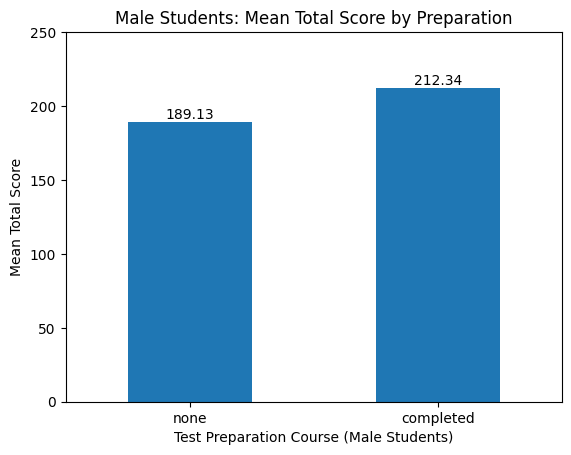

In [7]:
ax = male_stats['mean'].reindex(['none', 'completed']).plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.2f')

plt.xlabel('Test Preparation Course (Male Students)')
plt.ylabel('Mean Total Score')
plt.title('Male Students: Mean Total Score by Preparation')
plt.xticks(rotation=0)
plt.ylim(0, 250)
plt.show()

In [8]:
is_male_completed = (df['gender'] == 'male') & (df['test preparation course'] == 'completed')

group_a = df.loc[is_male_completed, 'total score']
group_b = df.loc[~is_male_completed, 'total score']

print('Male completed count and mean:', len(group_a), group_a.mean())
print('Everyone else count and mean:', len(group_b), group_b.mean())

t_stat2, p_value2 = stats.ttest_ind(group_a, group_b, equal_var=False)
print('t-statistic:', t_stat2)
print('p-value:', p_value2)

Male completed count and mean: 174 212.3448275862069
Everyone else count and mean: 826 201.409200968523
t-statistic: 3.257451981231156
p-value: 0.0012695902226222658


In [9]:
female = df[df['gender'] == 'female']

female_stats = female.groupby('test preparation course')['total score'].agg(['count', 'mean', 'std'])
print(female_stats)

female_completed = female.loc[female['test preparation course'] == 'completed', 'total score']
female_none = female.loc[female['test preparation course'] == 'none', 'total score']

female_t_stat, female_p_value = stats.ttest_ind(female_completed, female_none, equal_var=False)
print('Mean difference:', female_completed.mean() - female_none.mean())
print('t-statistic:', female_t_stat)
print('p-value:', female_p_value)

                         count        mean        std
test preparation course                              
completed                  184  223.364130  37.979330
none                       334  200.634731  44.475098
Mean difference: 22.72939989586044
t-statistic: 6.127090604233104
p-value: 2.026535575849405e-09


In [10]:
lunch_stats = df.groupby('lunch')['total score'].agg(['count', 'mean', 'std'])
print(lunch_stats)

standard = df.loc[df['lunch'] == 'standard', 'total score']
free_reduced = df.loc[df['lunch'] == 'free/reduced', 'total score']

lunch_t_stat, lunch_p_value = stats.ttest_ind(standard, free_reduced, equal_var=False)
print('Mean difference:', standard.mean() - free_reduced.mean())
print('t-statistic:', lunch_t_stat)
print('p-value:', lunch_p_value)

              count        mean        std
lunch                                     
free/reduced    355  186.597183  43.374971
standard        645  212.511628  39.559515
Mean difference: 25.914444808385184
t-statistic: 9.323207349610827
p-value: 1.582969042730361e-19


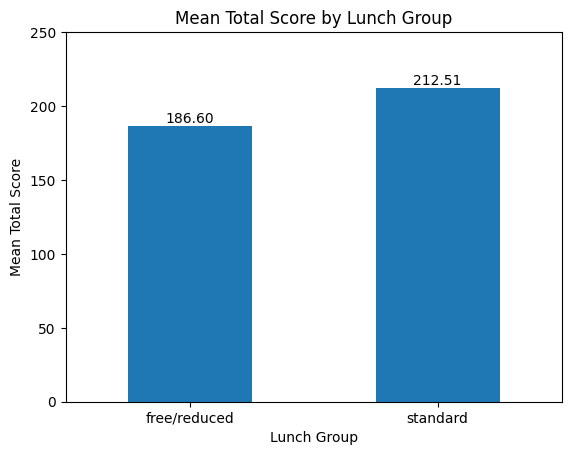

In [11]:
ax = lunch_stats['mean'].reindex(['free/reduced', 'standard']).plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.2f')

plt.xlabel('Lunch Group')
plt.ylabel('Mean Total Score')
plt.title('Mean Total Score by Lunch Group')
plt.xticks(rotation=0)
plt.ylim(0, 250)
plt.show()